# BÁO CÁO EDA – GITHUB REPOSITORY POPULARITY ANALYSIS

**Snapshot dữ liệu:** `2026-10-26 02:04:57 UTC`  
**Cỡ mẫu:** 12.000 repositories  
**Phạm vi:** dữ liệu CSV do nhóm cung cấp; thống kê mô tả, phân phối, ngôn ngữ, tuổi đời, tương quan, kiểm định và so sánh file chuẩn hóa.

> **Lưu ý về đầu vào:** không nhận được file Folder 01 sau imputation. Báo cáo dùng CSV raw làm mốc trước chuẩn hóa và giữ nguyên missing values. Không có `watchers_count`; Stars và Forks được phân tích riêng.

## Tóm tắt điều hành

- Bộ dữ liệu có 12.000 repositories, `star_count` từ 612 đến 393.057; đây là mẫu có ngưỡng Stars tối thiểu quan sát được, không đại diện mặc nhiên toàn GitHub.
- Stars/Forks/Open Issues/Size lệch phải rất mạnh; median phù hợp hơn mean để đại diện giá trị điển hình.
- Stars và Forks có tương quan dương mạnh; các tương quan Stars với Size, tuổi và số topics yếu hơn.
- Tuổi đời tính theo `collected_at - created_at`; snapshot chung là 26/10/2026 UTC.
- File Scale trùng hoàn toàn với Z-Score; Min-Max là biến đổi khác. Chỉ có hai bộ dữ liệu biến đổi phân biệt thực tế.

## RQ1 – Đặc điểm và chất lượng dữ liệu

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_common.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "analysis_common.py").is_file():
    raise FileNotFoundError("Không tìm thấy analysis_common.py trong thư mục dự án.")
sys.path.insert(0, str(PROJECT_ROOT))

import json
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from analysis_common import (
    load_raw_data, load_normalized_frames, prepare_analysis_frame,
    get_programming_language_frame, topic_frequency, save_figure,
    NUMERIC_METRICS, POPULARITY_METRICS, PROJECT_ROOT
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

from itertools import combinations
from statsmodels.stats.multitest import multipletests

raw = load_raw_data()
df = prepare_analysis_frame(raw)
lang_df = get_programming_language_frame(df)
norm = load_normalized_frames()
R = PROJECT_ROOT / "results"
O = PROJECT_ROOT / "outputs" / "report"
O.mkdir(parents=True, exist_ok=True)

# Compact input inventory (actual files shipped in this project package).
inventory = pd.read_csv(R / "input_inventory.csv")
display(inventory[["file","format","rows","columns","size_bytes","role"]])
print(f"Shape raw: {raw.shape}; repo_id unique: {raw.repo_id.nunique():,}; duplicated rows: {raw.duplicated().sum():,}")
print("Raw missing values:", raw.isna().sum().loc[lambda x:x>0].to_dict())
print("Count of watchers_count field:", int("watchers_count" in raw.columns))

,file,format,rows,columns,size_bytes,role
0,Văn bản đã dán (1).txt,TXT,"3,879 dòng văn bản",Không áp dụng,34646,Đặc tả yêu cầu dự án
1,01_github_repos_chua_chuan_hoa_raw.csv,CSV,12000,21,5602790,Dữ liệu gốc trước chuẩn hóa; dùng làm mốc EDA ...
2,scale_github_repos_binned.csv,CSV,12000,23,6527374,File tên Scale; nội dung thực tế trùng hoàn to...
3,zscore_github_repos_binned.csv,CSV,12000,23,6527374,Dữ liệu Z-Score / StandardScaler
4,minmax_github_repos_binned.csv,CSV,12000,23,6498883,Dữ liệu Min-Max
5,Bai03_Truc_quan.pdf,PDF,46 trang,Không áp dụng,1787031,Tài liệu học phần Bài 03
6,Bai04_Cong_cu_TQ.pdf,PDF,69 trang,Không áp dụng,2574802,Tài liệu học phần Bài 04
7,Bai05_PT_Tham_do.pdf,PDF,38 trang,Không áp dụng,2124540,Tài liệu học phần Bài 05
8,truc_quan_v2.ipynb,IPYNB,14 cells,8 Markdown + 6 code,884836,Notebook tham khảo phong cách và nội dung hiện...
9,tham_do_v2.ipynb,IPYNB,22 cells,12 Markdown + 10 code,970440,Notebook tham khảo cách tổ chức code Bài 05


Shape raw: (12000, 21); repo_id unique: 12,000; duplicated rows: 0
Raw missing values: {'description': 643, 'license_key': 1657}
Count of watchers_count field: 0


**Diễn giải:** mỗi dòng là một repository, định danh theo `repo_id` và `full_name`; các trường JSON `topics`, `languages` chứa danh sách. `star_count` là Stars; `forks_count` là Forks; không có Watchers. `description` và `license_key` là hai trường thiếu dữ liệu; các biến số chính của EDA không thiếu.

### RQ1 – Thống kê mô tả các biến quan trọng

In [2]:
NUM_COLS = ["star_count","forks_count","open_issues_count","size_kb","age_days","topic_count"]
def summarize(s, mode_ok=True):
    s = pd.to_numeric(s, errors="coerce").dropna().astype(float)
    q1, med, q3 = s.quantile([.25,.5,.75])
    mode = s.mode().iloc[0] if mode_ok and not s.mode().empty else np.nan
    return {"Count":s.count(),"Mean":s.mean(),"Median":med,"Mode":mode,"Std":s.std(),"Variance":s.var(),
            "Min":s.min(),"Q1":q1,"Q2":med,"Q3":q3,"IQR":q3-q1,"Max":s.max(),"Skewness":s.skew(),"Kurtosis":s.kurt()}
report_stats = pd.DataFrame({c:summarize(df[c], c!="age_days") for c in NUM_COLS}).T
report_stats.index.name = "variable"
report_stats.to_csv(R / "report_descriptive_statistics.csv", encoding="utf-8-sig")
display(report_stats.style.format("{:,.3f}"))

,Count,Mean,Median,Mode,Std,Variance,Min,Q1,Q2,Q3,IQR,Max,Skewness,Kurtosis
variable,,,,,,,,,,,,,,
star_count,"12,000.000","4,657.809","1,713.000",832.000,"13,516.042","182,683,383.388",612.000,"1,065.000","1,713.000","3,483.000","2,418.000","393,057.000",12.581,236.844
forks_count,"12,000.000",601.180,174.000,62.000,"2,518.165","6,341,155.924",0.000,88.000,174.000,392.000,304.000,"107,748.000",22.025,715.929
open_issues_count,"12,000.000",79.025,18.000,0.000,596.568,"355,893.342",0.000,5.000,18.000,53.000,48.000,"51,103.000",60.833,"4,755.688"
size_kb,"12,000.000","109,556.914","13,518.500",29.000,"889,179.717","790,640,569,281.039",0.000,"2,165.750","13,518.500","58,916.250","56,750.500","57,192,250.000",38.911,"1,971.066"
age_days,"12,000.000",573.869,573.936,nan,315.628,"99,620.989",25.392,299.918,573.936,847.463,547.545,"1,120.847",0.002,-1.201
topic_count,"12,000.000",7.039,4.000,4.000,5.049,25.496,0.000,4.000,4.000,9.000,5.000,20.000,1.310,0.671


**Phát hiện:** `star_count` mean lớn hơn median; độ lệch và kurtosis lớn cho thấy đuôi phải dài và có giá trị cực lớn. Range rất nhạy với các điểm xa; IQR mô tả 50% quan sát trung tâm tốt hơn khi phân phối lệch.

## RQ2 – Ngôn ngữ lập trình và Stars/Forks

,primary_language_clean,n,median_stars,q1_stars,q3_stars,median_forks,share_pct
0,Python,3846,"1,706",1071.000000,3498.500000,191,34.83%
1,TypeScript,2319,"1,943",1162.500000,4204.500000,208,21.00%
2,JavaScript,747,"1,718",1062.000000,3245.500000,230,6.77%
3,Rust,710,"1,869",1110.250000,3957.750000,128,6.43%
4,Go,576,"1,744",1098.500000,3642.500000,156,5.22%
5,C++,313,"1,367",919.000000,2961.000000,151,2.83%
6,Jupyter Notebook,275,"1,766",1066.000000,4100.500000,273,2.49%
7,Shell,259,"1,527",962.000000,3219.000000,158,2.35%
8,Swift,242,"1,842",1096.500000,3209.000000,132,2.19%
9,HTML,241,"1,703",1040.000000,3675.000000,214,2.18%


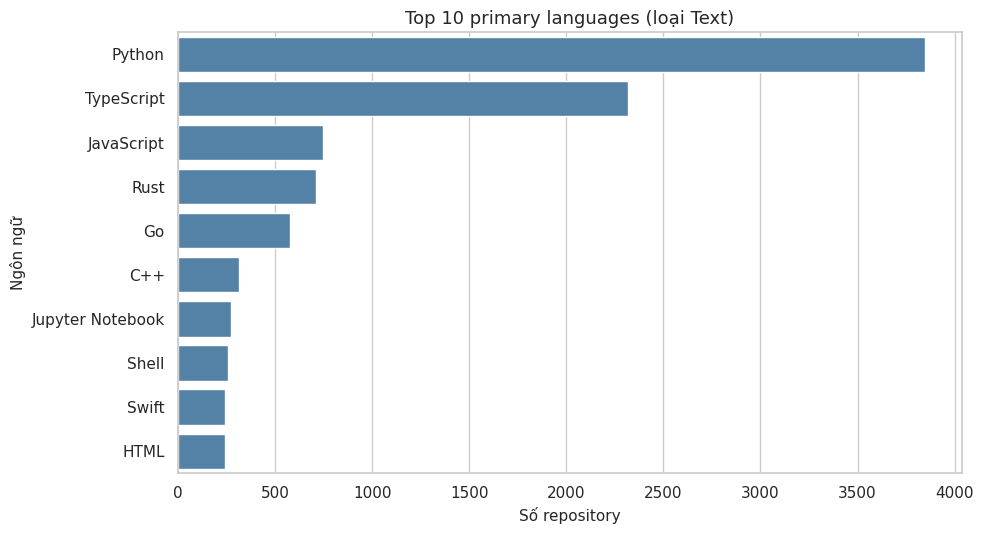

In [3]:
lang_counts = lang_df["primary_language_clean"].value_counts()
top5 = lang_counts.head(5).index.tolist()
lang_report = lang_df.groupby("primary_language_clean").agg(
    n=("repo_id","size"), median_stars=("star_count","median"), q1_stars=("star_count",lambda s:s.quantile(.25)),
    q3_stars=("star_count",lambda s:s.quantile(.75)), median_forks=("forks_count","median")
).sort_values("n",ascending=False).head(10).reset_index()
lang_report["share_pct"] = lang_report["n"] / len(lang_df) * 100
lang_report.to_csv(R / "report_language_summary.csv", index=False, encoding="utf-8-sig")
display(lang_report.style.format({"share_pct":"{:.2f}%","median_stars":"{:,.0f}","median_forks":"{:,.0f}"}))
fig, ax = plt.subplots(figsize=(10,5.5))
sns.barplot(data=lang_report, x="n", y="primary_language_clean", color="steelblue", ax=ax)
ax.set(title="Top 10 primary languages (loại Text)", xlabel="Số repository", ylabel="Ngôn ngữ")
fig.tight_layout(); save_figure(fig, O/"report_top_languages.png"); plt.show()

**Lưu ý:** 958 dòng có `primary_language = text` được loại khỏi phân tích tỷ lệ ngôn ngữ lập trình, nhưng vẫn giữ trong phân tích số trên toàn bộ 12.000 repo. Bảng median Stars/Forks trình bày riêng từng chỉ số, không tạo popularity score tổng hợp.

## RQ3 – Tuổi đời repository và Stars

,n,mean_years,median_years,q1_years,q3_years,min_years,max_years
0,"12,000.000",1.571,1.571,0.821,2.320,0.070,3.069


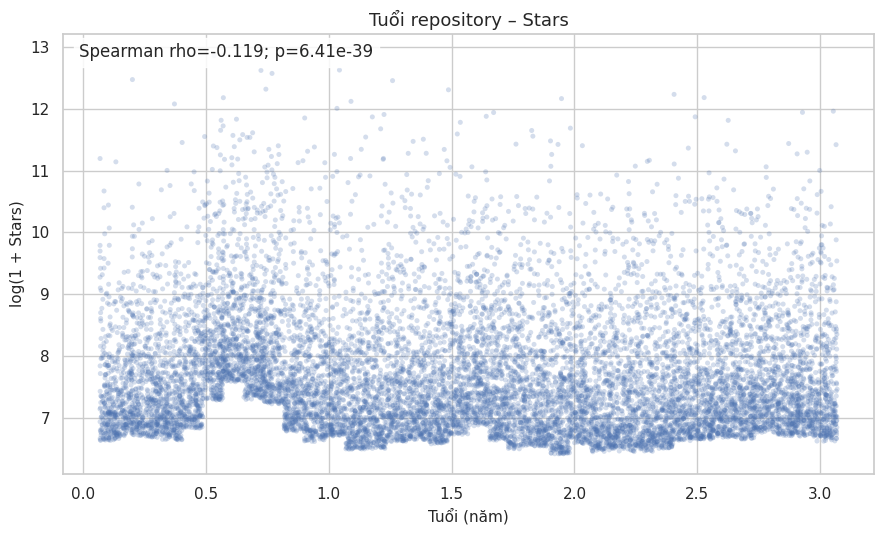

Snapshot = 2026-10-26 02:04:57+00:00; Age–Stars rho=-0.1187, p=6.409e-39


In [4]:
age = df["age_years"].dropna()
age_stats = pd.DataFrame([{"n":age.count(),"mean_years":age.mean(),"median_years":age.median(),
                           "q1_years":age.quantile(.25),"q3_years":age.quantile(.75),
                           "min_years":age.min(),"max_years":age.max()}])
age_stats.to_csv(R/"report_age_summary.csv", index=False, encoding="utf-8-sig")
display(age_stats.style.format("{:,.3f}"))
sp_age = stats.spearmanr(df["age_days"],df["star_count"])
fig, ax = plt.subplots(figsize=(9,5.5))
ax.scatter(df["age_years"],np.log1p(df["star_count"]),s=13,alpha=.24,edgecolors="none")
ax.set(title="Tuổi repository – Stars",xlabel="Tuổi (năm)",ylabel="log(1 + Stars)")
ax.text(.02,.98,f"Spearman rho={sp_age.statistic:.3f}; p={sp_age.pvalue:.2e}",transform=ax.transAxes,va="top",bbox={"facecolor":"white","alpha":.85})
fig.tight_layout(); save_figure(fig,O/"report_age_stars.png"); plt.show()
print(f"Snapshot = {df['collected_at_dt'].min()}; Age–Stars rho={sp_age.statistic:.4f}, p={sp_age.pvalue:.3e}")

**Diễn giải:** tuổi đời trung bình và trung vị được tính tại snapshot chung 26/10/2026 UTC. Nếu Spearman âm, điều đó chỉ nói tuổi xếp hạng lớn hơn có xu hướng đi cùng Stars thấp hơn trong mẫu này; không chứng minh repository càng mới càng phổ biến.

## RQ4 – Tương quan giữa Stars và các biến số

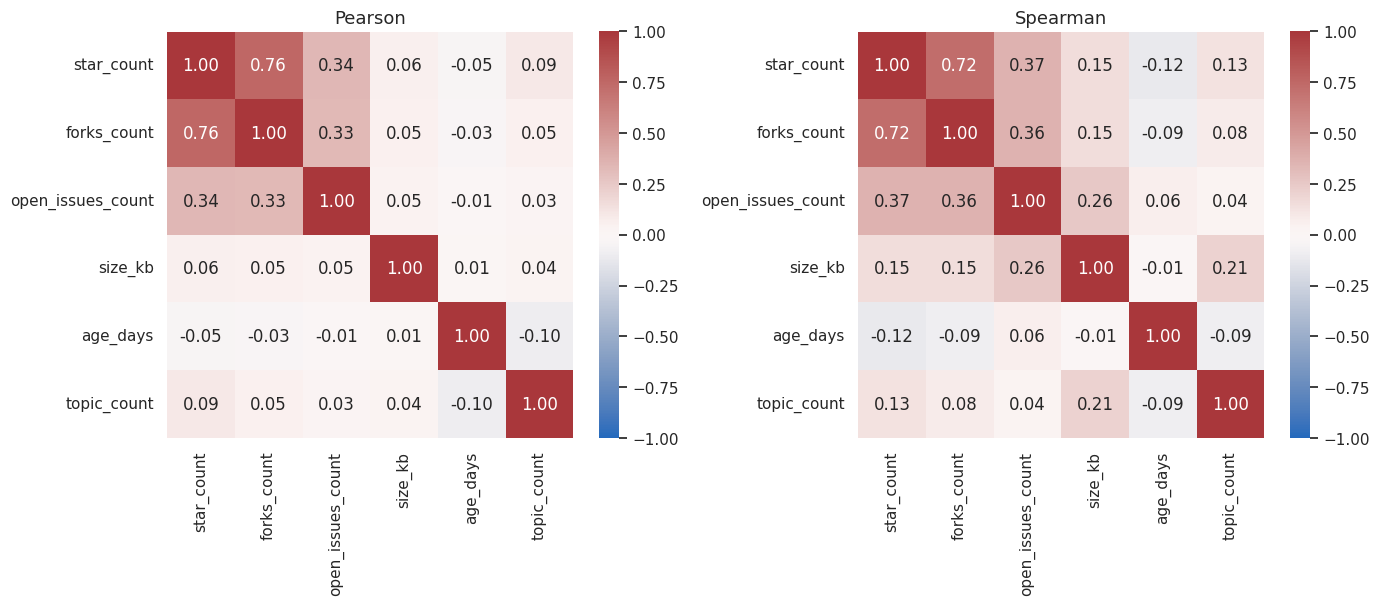

In [5]:
cols = ["star_count","forks_count","open_issues_count","size_kb","age_days","topic_count"]
pear = df[cols].corr(method="pearson")
spear = df[cols].corr(method="spearman")
pear.to_csv(R/"report_pearson_matrix.csv", encoding="utf-8-sig")
spear.to_csv(R/"report_spearman_matrix.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1,2,figsize=(14,5.8))
sns.heatmap(pear,annot=True,fmt=".2f",cmap="vlag",vmin=-1,vmax=1,center=0,ax=axes[0],square=True); axes[0].set_title("Pearson")
sns.heatmap(spear,annot=True,fmt=".2f",cmap="vlag",vmin=-1,vmax=1,center=0,ax=axes[1],square=True); axes[1].set_title("Spearman")
fig.tight_layout(); save_figure(fig,O/"report_correlation_matrices.png"); plt.show()

**Diễn giải:** Pearson nhạy với giá trị cực lớn; Spearman cung cấp góc nhìn về quan hệ thứ hạng. Cần phân biệt độ lớn của hệ số với ý nghĩa thống kê, đặc biệt ở N = 12.000.

## Kiểm định thống kê

In [6]:
# RQ3: Spearman test
# RQ2: Kruskal-Wallis (primary) and Welch ANOVA (sensitivity check)
groups=[lang_df.loc[lang_df.primary_language_clean==g,"star_count"].to_numpy() for g in top5]
kw=stats.kruskal(*groups)
try: welch=stats.f_oneway(*groups,equal_var=False); welch_name="Welch ANOVA"
except TypeError: welch=stats.f_oneway(*groups); welch_name="One-way ANOVA fallback"
eps2=(kw.statistic-len(groups)+1)/(sum(map(len,groups))-len(groups))
test_report=pd.DataFrame([
 {"question":"Age–Stars","H0":"Spearman rho = 0","test":"Spearman","statistic":sp_age.statistic,"p_value":sp_age.pvalue,"effect":"rho","effect_size":sp_age.statistic,"alpha":.05},
 {"question":"Stars by Top 5 languages","H0":"Same Stars rank distribution in all groups","test":"Kruskal-Wallis","statistic":kw.statistic,"p_value":kw.pvalue,"effect":"epsilon-squared","effect_size":eps2,"alpha":.05},
 {"question":"Mean Stars by Top 5 languages (sensitivity)","H0":"Equal group means","test":welch_name,"statistic":welch.statistic,"p_value":welch.pvalue,"effect":"F statistic","effect_size":np.nan,"alpha":.05},
])
test_report["decision"] = np.where(test_report.p_value < .05,"Bác bỏ H0","Chưa đủ bằng chứng bác bỏ H0")
test_report.to_csv(R/"report_statistical_tests.csv",index=False,encoding="utf-8-sig")
display(test_report.style.format({"statistic":"{:.4f}","p_value":"{:.3e}","effect_size":"{:.4f}"}))

,question,H0,test,statistic,p_value,effect,effect_size,alpha,decision
0,Age–Stars,Spearman rho = 0,Spearman,-0.1187,6.409e-39,rho,-0.1187,0.050000,Bác bỏ H0
1,Stars by Top 5 languages,Same Stars rank distribution in all groups,Kruskal-Wallis,31.8041,2.098e-06,epsilon-squared,0.0034,0.050000,Bác bỏ H0
2,Mean Stars by Top 5 languages (sensitivity),Equal group means,Welch ANOVA,2.0703,8.223e-02,F statistic,nan,0.050000,Chưa đủ bằng chứng bác bỏ H0


**Kết luận kiểm định:** Kruskal–Wallis là kiểm định chính cho khác biệt thứ hạng/phân phối Stars giữa Top 5 ngôn ngữ. Epsilon-squared cần được đọc kèm p-value; p nhỏ không đồng nghĩa hiệu ứng lớn. Welch ANOVA chỉ là phân tích nhạy cảm về trung bình, không thay thế câu hỏi về trung vị.

## RQ5/RQ6 – So sánh ba file chuẩn hóa

In [7]:
raw_ids=raw.repo_id.reset_index(drop=True)
integrity=[]
for name, frame in norm.items():
    integrity.append({"file":name,"rows":len(frame),"same_ID_set":set(raw.repo_id)==set(frame.repo_id),
                      "same_order":raw_ids.equals(frame.repo_id.reset_index(drop=True)),
                      "duplicate_IDs":frame.repo_id.duplicated().sum()})
integrity=pd.DataFrame(integrity)
integrity.to_csv(R/"report_normalization_integrity.csv",index=False,encoding="utf-8-sig")
display(integrity)
scale_equals_z=norm["Scale"].equals(norm["Z-Score"])
print("Scale and Z-Score files identical:",scale_equals_z)

norm_rows=[]
for name,frame in [("Raw",raw)]+list(norm.items()):
    s=frame["star_count"]
    q1,q3=s.quantile([.25,.75])
    norm_rows.append({"dataset":name,"mean":s.mean(),"median":s.median(),"std_sample":s.std(),"min":s.min(),"q1":q1,"q3":q3,"iqr":q3-q1,"max":s.max(),"skewness":s.skew()})
norm_summary=pd.DataFrame(norm_rows)
norm_summary.to_csv(R/"report_normalization_star_stats.csv",index=False,encoding="utf-8-sig")
display(norm_summary.style.format({c:"{:,.5f}" for c in norm_summary.select_dtypes(include="number").columns}))

,file,rows,same_ID_set,same_order,duplicate_IDs
0,Scale,12000,True,True,0
1,Z-Score,12000,True,True,0
2,Min-Max,12000,True,True,0


Scale and Z-Score files identical: True


,dataset,mean,median,std_sample,min,q1,q3,iqr,max,skewness
0,Raw,"4,657.80883","1,713.00000","13,516.04171",612.00000,"1,065.00000","3,483.00000","2,418.00000","393,057.00000",12.58136
1,Scale,0.00000,-0.21788,1.00004,-0.29935,-0.26583,-0.08692,0.17891,28.73736,12.58136
2,Z-Score,0.00000,-0.21788,1.00004,-0.29935,-0.26583,-0.08692,0.17891,28.73736,12.58136
3,Min-Max,0.01031,0.00281,0.03444,0.00000,0.00115,0.00732,0.00616,1.00000,12.58136


In [8]:
norm_corr=[]
for name,frame in [("Raw",raw)]+list(norm.items()):
    norm_corr.append({"dataset":name,"Pearson Stars–Forks":stats.pearsonr(frame.star_count,frame.forks_count).statistic,
                      "Spearman Stars–Forks":stats.spearmanr(frame.star_count,frame.forks_count).statistic})
norm_corr=pd.DataFrame(norm_corr)
norm_corr.to_csv(R/"report_normalization_correlation.csv",index=False,encoding="utf-8-sig")
display(norm_corr.style.format({"pearson_r":"{:.10f}", "spearman_rho":"{:.10f}"}))

,dataset,Pearson Stars–Forks,Spearman Stars–Forks
0,Raw,0.757367,0.723438
1,Scale,0.757367,0.723438
2,Z-Score,0.757367,0.723438
3,Min-Max,0.757367,0.723438


**Đánh giá phương pháp:**

- `zscore_github_repos_binned.csv` có mean xấp xỉ 0 và độ lệch chuẩn tổng thể xấp xỉ 1 trên bốn biến số được biến đổi, phù hợp đặc trưng Z-Score/StandardScaler.
- `scale_github_repos_binned.csv` giống hệt Z-Score ở mọi cột, mọi dòng; không thể tính là một phương pháp khác.
- `minmax_github_repos_binned.csv` đưa bốn biến số về [0, 1].
- Cả ba file giữ cùng `repo_id`, cùng thứ tự; các cột phân loại/ngày/text giữ nguyên và hai cột `star-bin`, `fork-bin` được thêm vào.
- Min-Max và Z-Score là biến đổi tuyến tính dương theo từng cột nên thứ hạng và tương quan Pearson/Spearman được bảo toàn về lý thuyết (sai khác chỉ do sai số số học). Chọn phương pháp phụ thuộc mô hình downstream: thang 0–1 có thể tiện cho thuật toán cần miền chặn; Z-Score thường hữu ích khi cần biến có độ lệch chuẩn tương đương. Không có một lựa chọn “tốt nhất” nếu chưa có mục tiêu mô hình cụ thể.

## Kết luận và hạn chế

**Kết luận chính:** Stars có tương quan mạnh với Forks; Stars lệch phải; ngôn ngữ lập trình có thể khác nhau về phân phối thứ hạng Stars nhưng cần đọc effect size; tuổi đời có liên hệ yếu với Stars trong mẫu; ba tên file chuẩn hóa chỉ đại diện hai kết quả khác nhau do Scale trùng Z-Score.

**Hạn chế:** (1) mẫu 12.000 repo, Stars tối thiểu 612, phương pháp chọn mẫu không có trong tài liệu; (2) không có Watchers; (3) không có CSV Folder 01 đã impute; (4) timestamp update/push có bất thường so với snapshot; (5) kiểm định quan sát không suy ra nhân quả; (6) không thể đưa ra phương pháp chuẩn hóa tối ưu khi chưa đánh giá một pipeline mô hình cụ thể.